# 04 - Forecast, submission file, economics
Hindcast-validated decline forecast (liquid rate x water cut) to 2028 for the 10 best sets; fills the template, calculates NPV and exports Power BI tables.

In [1]:
# SETUP - run this cell first, every time you open the notebook.
# It connects Google Drive, installs one extra package and loads our helper code.
import os, sys, subprocess, importlib
try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = '/content/drive/MyDrive/DWC26'          # the shared team folder
except ImportError:                                 # (only used when running outside Colab)
    BASE = os.environ.get('DWC_BASE', 'DWC26')
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'python-calamine'], check=False, capture_output=True)
sys.path.insert(0, f'{BASE}/notebooks')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import dwc_utils as du; importlib.reload(du)
P = du.get_paths(BASE)
pd.set_option('display.float_format', lambda x: f'{x:,.4g}')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
print('Ready. Project folder:', BASE)

Mounted at /content/drive
Ready. Project folder: /content/drive/MyDrive/DWC26


In [2]:
import joblib
du.require(f"{P['PROC']}/best10_scaled.npy", 'notebook 03')
A = np.load(f"{P['PROC']}/arrays.npz")
grid = pd.to_datetime(A['grid']); gx = du.day_number(grid)
params = pd.read_parquet(f"{P['PROC']}/params.parquet").set_index('case_id').loc[A['case_ids']].reset_index()
Y = {v: A[v] for v in du.CUMS}; OBS = {v: A['obs_' + v] for v in du.CUMS}
M = joblib.load(f"{P['PROC']}/proxy.joblib")
best10_s = np.load(f"{P['PROC']}/best10_scaled.npy")
BEST10 = pd.read_csv(f"{P['OUT']}/best10_parameters.csv")
FILES = du.find_raw_files(P['RAW'])
print('History ends', grid[-1].date())

History ends 2008-01-01


### Step 1 - Gas-oil ratio

In [3]:
GOR = float(np.median(Y['gas_cum'][:, -1] / Y['oil_cum'][:, -1]))
gor_obs = float(np.nanmedian(OBS['gas_cum'][-8:] / OBS['oil_cum'][-8:]))
print(f'GOR from simulated cases = {GOR:.4f} MSCF/barrel;  real field (last 2 years) = {gor_obs:.4f}')

GOR from simulated cases = 0.3632 MSCF/barrel;  real field (last 2 years) = 0.3633


### Step 2 - Hindcast (fit to 2004, test on 2005-2008)

In [4]:
CUT = '2005-01-01'
t_cut = du.day_number([CUT])[0]
after = gx > t_cut
rows = []
for i, cid in enumerate(params.case_id):
    o_true, w_true = Y['oil_cum'][i][after], Y['water_cum'][i][after]
    row = {'case_id': cid}
    for name, bmax in [('hyperbolic', 1.0), ('exponential', 0.05)]:
        try:
            fc, _ = du.fit_forecaster(gx, Y['oil_cum'][i], Y['water_cum'][i], t_cut, b_max=bmax)
            o, w = fc(gx[after])
            row[f'{name}_oil_err_%'] = abs(o[-1] - o_true[-1]) / o_true[-1] * 100
            row[f'{name}_water_err_%'] = abs(w[-1] - w_true[-1]) / max(w_true[-1], 1) * 100
        except Exception as e:
            row[f'{name}_note'] = str(e)[:60]
    try:
        o = du.fit_oil_only_arps(gx, Y['oil_cum'][i], t_cut)(gx[after])
        row['oil-only_oil_err_%'] = abs(o[-1] - o_true[-1]) / o_true[-1] * 100
    except Exception as e:
        row['oil-only_note'] = str(e)[:60]
    rows.append(row)
HC = pd.DataFrame(rows); HC.to_csv(f"{P['OUT']}/hindcast_results.csv", index=False)
err_cols = [c for c in HC.columns if c.endswith('err_%')]
summary = HC[err_cols].describe().loc[['count', 'mean', '50%', 'max']].round(2)
display(summary)
score_h = HC['hyperbolic_oil_err_%'].median() + HC['hyperbolic_water_err_%'].median()
score_e = HC['exponential_oil_err_%'].median() + HC['exponential_water_err_%'].median()
B_MAX = 1.0 if score_h <= score_e else 0.05
print('Chosen method: liquid x water cut with', 'hyperbolic' if B_MAX == 1.0 else 'exponential', 'decline')

,hyperbolic_oil_err_%,hyperbolic_water_err_%,exponential_oil_err_%,exponential_water_err_%,oil-only_oil_err_%
count,100,100,100,100,100
mean,3.66,4.73,3.66,4.73,1.73
50%,4.18,4.23,4.18,4.23,2.11
max,7.62,11.08,7.62,11.08,3.63


Chosen method: liquid x water cut with exponential decline


### Step 3 - Forecast 2008-2028 for the 10 best sets

In [5]:
tpl_sheets = pd.read_excel(FILES['09'], sheet_name=None, engine='calamine')     # every sheet of the template
all_dates = pd.concat([du.to_dates(s.iloc[:, 0]) for s in tpl_sheets.values()]).dropna()
FUT_DATES = pd.Series(sorted(all_dates.unique()))                               # every date any sheet asks for
FUT = du.day_number(FUT_DATES)
print(f'Template sheets: {list(tpl_sheets)}')
print(f'Forecast dates: {FUT_DATES.iloc[0].date()} to {FUT_DATES.iloc[-1].date()} ({len(FUT_DATES)} dates)')
curves10 = {v: M['proxy'][v].predict(best10_s) for v in du.CUMS}
obs_end = {v: OBS[v][-1] for v in du.CUMS}
FORECASTS, fit_info = {}, []
for k in range(10):
    fc, info = du.fit_forecaster(gx, curves10['oil_cum'][k], curves10['water_cum'][k], b_max=B_MAX)
    o, w = fc(FUT)
    o = o + obs_end['oil_cum'] - curves10['oil_cum'][k][-1]          # anchor to the real 2008 total
    w = w + obs_end['water_cum'] - curves10['water_cum'][k][-1]
    g = obs_end['gas_cum'] + GOR * (o - obs_end['oil_cum'])
    FORECASTS[k + 1] = {'oil_cum': o, 'gas_cum': g, 'water_cum': w}
    fit_info.append({'rank': k + 1, **info})
display(pd.DataFrame(fit_info).round(3))

Template sheets: ['Case 1', 'Case 2', 'Case 3', 'Case 4', 'Case 5', 'Case 6', 'Case 7', 'Case 8', 'Case 9', 'Case 10']
Forecast dates: 2008-04-01 to 2028-01-01 (80 dates)


,rank,decline_start,qi,Di,b,wc_max,wc_mid,wc_width
0,1,2001-10-01,1.781e+04,0.063,0.05,0.675,2.831e+07,7.173e+06
1,2,2001-10-01,1.781e+04,0.063,0.05,0.675,2.831e+07,7.155e+06
2,3,2001-10-01,1.781e+04,0.063,0.05,0.677,2.829e+07,7.165e+06
3,4,2001-10-01,1.781e+04,0.063,0.05,0.675,2.831e+07,7.199e+06
4,5,2001-10-01,1.782e+04,0.063,0.05,0.672,2.828e+07,7.199e+06
5,6,2001-10-01,1.782e+04,0.064,0.05,0.677,2.835e+07,7.191e+06
6,7,2001-10-01,1.782e+04,0.063,0.05,0.672,2.822e+07,7.218e+06
7,8,2001-10-01,1.782e+04,0.062,0.05,0.671,2.82e+07,7.204e+06
8,9,2001-10-01,1.782e+04,0.063,0.05,0.669,2.824e+07,7.233e+06
9,10,2001-10-01,1.783e+04,0.063,0.05,0.671,2.827e+07,7.241e+06


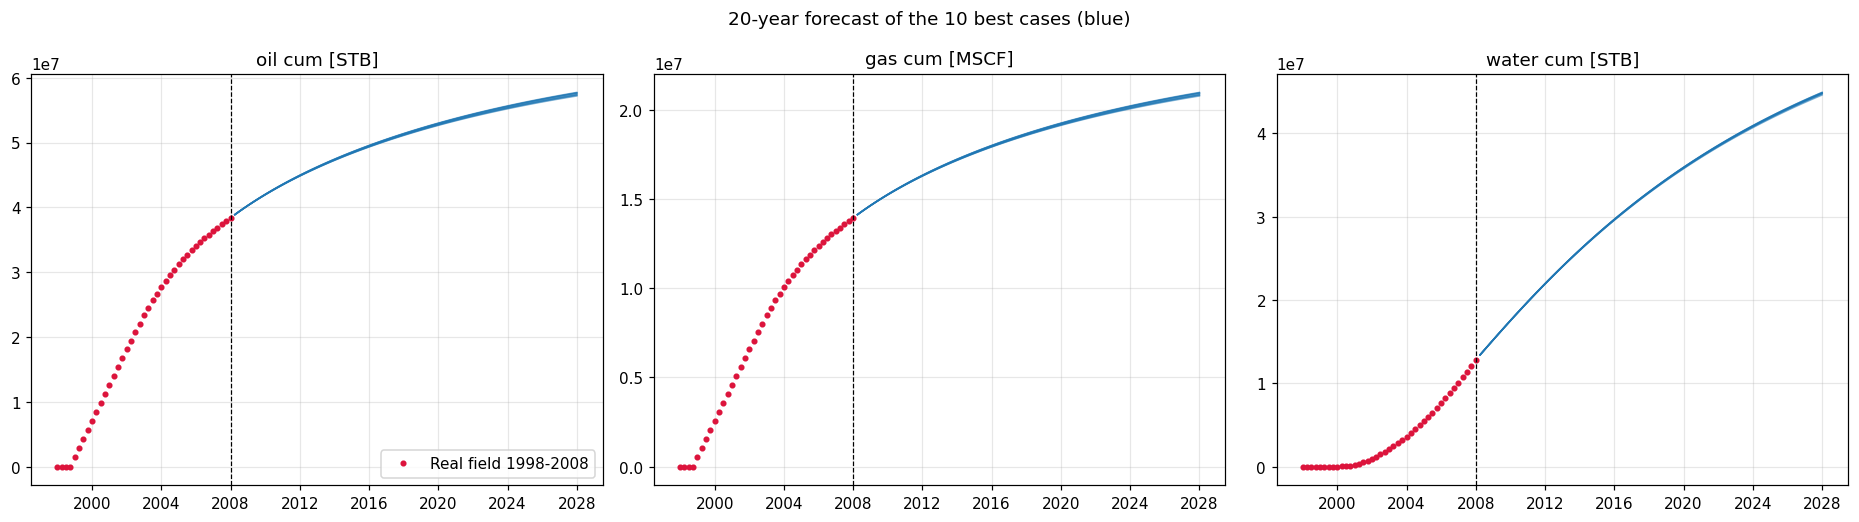

Cumulative production at 2028-01-01:


,oil_cum,gas_cum,water_cum
P10 (low),5.725e+07,2.08e+07,4.467e+07
P50 (middle),5.75e+07,2.089e+07,4.481e+07
P90 (high),5.768e+07,2.095e+07,4.491e+07


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
for a, v in zip(ax, du.CUMS):
    a.plot(grid, OBS[v], 'o', color='crimson', ms=3, label='Real field 1998-2008')
    for k in range(1, 11):
        a.plot(FUT_DATES, FORECASTS[k][v], color='tab:blue', alpha=0.5, lw=1)
    a.axvline(grid[-1], color='k', ls='--', lw=0.8); a.set_title(f"{v.replace('_', ' ')} [{du.UNITS[v]}]")
ax[0].legend(); fig.suptitle('20-year forecast of the 10 best cases (blue)'); fig.tight_layout()
fig.savefig(f"{P['FIG']}/10_forecast.png", bbox_inches='tight'); plt.show()
end = pd.DataFrame({v: [FORECASTS[k][v][-1] for k in range(1, 11)] for v in du.CUMS})
p = end.quantile([0.1, 0.5, 0.9]); p.index = ['P10 (low)', 'P50 (middle)', 'P90 (high)']
print(f'Cumulative production at {FUT_DATES.iloc[-1].date()}:'); display(p.round(-3))

### Step 4 - Fill the template -> `outputs/DWC26_Deliverable.xlsx`

In [7]:
import re
from openpyxl import load_workbook
OUT_XLSX = f"{P['OUT']}/DWC26_Deliverable.xlsx"
wb = load_workbook(FILES['09'])                                   # the template, formatting kept
numbered = sorted([(int(re.findall(r'\d+', ws.title)[-1]), ws) for ws in wb.worksheets if re.findall(r'\d+', ws.title)],
                  key=lambda t: t[0])                             # sheets with a number in the name, e.g. 'Case 1'..'Case 10'
if len(numbered) >= 10:                                           # template has one sheet per case: fill them, keep their names
    targets = [ws for _, ws in numbered[:10]]
else:                                                             # single-sheet template: make 10 copies Case_01..Case_10
    base = wb.worksheets[0]
    targets = [base] + [wb.copy_worksheet(base) for _ in range(9)]
    for k, ws in enumerate(targets, start=1):
        ws.title = f'Case_{k:02d}'
for k, ws in enumerate(targets, start=1):                         # sheet k gets forecast rank k (1 = best match)
    header = [str(c.value).strip() if c.value is not None else '' for c in ws[1]]
    COLS = {v: header.index(t) + 1 for v, t in du.TEMPLATE_COLUMNS.items() if t in header}
    if len(COLS) < 3:                                             # fallback: columns B, C, D
        COLS = {'gas_cum': 2, 'oil_cum': 3, 'water_cum': 4}
    for r in range(2, ws.max_row + 1):                            # every row under the headings
        val = ws.cell(r, 1).value
        if val is None: continue
        d = du.to_dates(pd.Series([val]))
        if d.isna().iloc[0]: continue                             # not a date -> skip
        day = du.day_number(d)[0]
        for v, c in COLS.items():
            ws.cell(r, c).value = round(float(np.interp(day, FUT, FORECASTS[k][v])), 2)
wb.save(OUT_XLSX)
check = pd.read_excel(OUT_XLSX, sheet_name=None, engine='calamine')
filled = [ws.title for ws in targets]
print('Saved', OUT_XLSX)
print('Filled sheets (best match first):', filled)
good = all(not check[n].iloc[:, 1:4].isna().any().any()
           and (check[n].iloc[:, 1:4].astype(float).diff().dropna() >= 0).all().all() for n in filled)
print('All 10 sheets filled, no blanks, values always increase:', good)
for n in filled:
    print(f'  {n}: {len(check[n])} rows, {check[n].iloc[0, 0]} to {check[n].iloc[-1, 0]}')
display(check[filled[0]].head(3)); display(check[filled[0]].tail(2))

Saved /content/drive/MyDrive/DWC26/outputs/DWC26_Deliverable.xlsx
Filled sheets (best match first): ['Case 1', 'Case 2', 'Case 3', 'Case 4', 'Case 5', 'Case 6', 'Case 7', 'Case 8', 'Case 9', 'Case 10']
All 10 sheets filled, no blanks, values always increase: True
  Case 1: 40 rows, 04/01/2008 to 01/01/2018
  Case 2: 80 rows, 04/01/2008 to 2028-01-01 00:00:00
  Case 3: 80 rows, 04/01/2008 to 2028-01-01 00:00:00
  Case 4: 80 rows, 04/01/2008 to 2028-01-01 00:00:00
  Case 5: 80 rows, 04/01/2008 to 2028-01-01 00:00:00
  Case 6: 80 rows, 04/01/2008 to 2028-01-01 00:00:00
  Case 7: 80 rows, 04/01/2008 to 2028-01-01 00:00:00
  Case 8: 80 rows, 04/01/2008 to 2028-01-01 00:00:00
  Case 9: 80 rows, 04/01/2008 to 2028-01-01 00:00:00
  Case 10: 80 rows, 04/01/2008 to 2028-01-01 00:00:00


,Date,Gas production cumulative [MSCF],Oil production cumulative [STB],Water production cumulative [STB]
0,04/01/2008,1.412e+07,3.887e+07,1.341e+07
1,07/01/2008,1.429e+07,3.935e+07,1.401e+07
2,10/01/2008,1.446e+07,3.981e+07,1.461e+07


,Date,Gas production cumulative [MSCF],Oil production cumulative [STB],Water production cumulative [STB]
38,10/01/2017,1.852e+07,5.097e+07,3.256e+07
39,01/01/2018,1.859e+07,5.119e+07,3.296e+07


### Step 5 - Economics (assumed prices)

In [8]:
OIL_PRICE = 70.0        # USD per barrel (assumption)
GAS_PRICE = 3.0         # USD per MSCF (assumption)
WATER_COST = 2.0        # USD per barrel of water handled (assumption)
OPEX = 60e6             # USD per year fixed operating cost (assumption)
DISCOUNT = 0.10         # 10% per year
cash, npv = [], []
dates_with_start = pd.concat([pd.Series([grid[-1]]), FUT_DATES.reset_index(drop=True)])
for k in range(1, 11):
    cf = du.yearly_cashflow(dates_with_start,
                            np.r_[obs_end['oil_cum'], FORECASTS[k]['oil_cum']], np.r_[obs_end['gas_cum'], FORECASTS[k]['gas_cum']],
                            np.r_[obs_end['water_cum'], FORECASTS[k]['water_cum']], OIL_PRICE, GAS_PRICE, WATER_COST, OPEX, DISCOUNT)
    cf['rank'] = k; cash.append(cf); npv.append(cf['discounted_usd'].sum())
cash = pd.concat(cash, ignore_index=True)
NPV = pd.Series(npv, index=range(1, 11), name='NPV_usd')
print('NPV 2008-2028 per case (million USD):'); display((NPV / 1e6).round(0).to_frame().T)
print(f'P10 / P50 / P90 NPV: {np.percentile(NPV, 10)/1e6:,.0f} / {np.percentile(NPV, 50)/1e6:,.0f} / {np.percentile(NPV, 90)/1e6:,.0f} million USD')
yearly = cash.groupby('year')['net_cash_usd'].median() / 1e6
first_loss = yearly[yearly < 0].index.min()
print('Median case turns loss-making in', first_loss if pd.notna(first_loss) else 'no year before 2028')

NPV 2008-2028 per case (million USD):


,1,2,3,4,5,6,7,8,9,10
NPV_usd,155,154,151,157,164,149,165,166,169,164


P10 / P50 / P90 NPV: 151 / 160 / 166 million USD
Median case turns loss-making in 2018


### Step 6 - Tables for Power BI

In [9]:
params_out = params.copy()
gf = f"{P['PROC']}/grid_features.parquet"
if os.path.exists(gf): params_out = params_out.merge(pd.read_parquet(gf), on='case_id', how='left')
params_out.to_csv(f"{P['PBI']}/cases.csv", index=False)
rows = []
for i, cid in enumerate(params.case_id):
    for v in du.CUMS:
        rows.append(pd.DataFrame({'case': f'Case {cid}', 'date': grid, 'variable': v, 'value': Y[v][i], 'source': 'simulated'}))
for v in du.CUMS:
    rows.append(pd.DataFrame({'case': 'Real field', 'date': grid, 'variable': v, 'value': OBS[v], 'source': 'observed'}))
for k in range(1, 11):
    for v in du.CUMS:
        rows.append(pd.DataFrame({'case': f'Forecast {k:02d}', 'date': FUT_DATES.values, 'variable': v, 'value': FORECASTS[k][v], 'source': 'forecast'}))
prod = pd.concat(rows, ignore_index=True).dropna(subset=['value'])
prod.to_csv(f"{P['PBI']}/production_long.csv", index=False)
BEST10.assign(NPV_musd=NPV.values / 1e6).to_csv(f"{P['PBI']}/best10.csv", index=False)
cash.to_csv(f"{P['PBI']}/cashflow.csv", index=False)
g1 = f"{P['PROC']}/grid_full/case_001.parquet"
if os.path.exists(g1):
    g = pd.read_parquet(g1); g = g[(g['PORV'] > 0)]
    g[[c for c in ['I', 'J', 'K', 'X', 'Y', 'Z', 'PORO', 'PERMX', 'SOIL'] if c in g]].to_csv(f"{P['PBI']}/grid_case1.csv", index=False)
print('Power BI files:', sorted(os.listdir(P['PBI'])))

Power BI files: ['best10.csv', 'cases.csv', 'cashflow.csv', 'grid_case1.csv', 'hm_samples.csv', 'production_long.csv', 'proxy_metrics.csv']
